# ULTIMATE–Subaru expanded ML validation

Executed training and evaluation companion. The pre-existing pipeline completed one frozen final20 evaluation; supplementary models here remain validation-only. Results concern signed DR1 paired-image differences; source-control residuals prevent equating numerical prediction accuracy with calibrated physical dust recovery.

The full benchmark is implemented in `model_study.py`; exact input hashes and tuning choices are saved. This notebook independently refits representative photometric and spatial ridge models using those development-only choices and checks held-out predictions against the benchmark.

In [1]:
from pathlib import Path
import sys,json
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Image
O=Path.cwd()
assert '/phd/' in sys.executable
sys.path.insert(0,str(O))
from model_study import estimator,feature_cols,TARGETS
f=pd.read_csv(O/'feature_table.csv.gz'); y=pd.read_csv(O/'target_table.csv')
settings=json.loads((O/'model_settings.json').read_text())
pred=pd.read_csv(O/'heldout_predictions.csv.gz')
print('Independent galaxies:',f.groupby('partition').subhalo_id.nunique().to_dict())
assert not f.partition.eq('final_test').any() and not y.partition.eq('final_test').any()


Independent galaxies: {'development': 86, 'validation': 14}


## Methods and physical definitions

Five views and four noise draws remain with their parent galaxy. Fitting and five-fold hyperparameter selection use nonzero-projected-dust development galaxies only; validation14 never selects settings. Native targets use a common fixed12-kpc or observed-Ks adaptive aperture for both scenes. C=5 log10(R80/R20); Δ denotes dusty minus clear. Integrated attenuation is −2.5 log10(F_dusty/F_clear). Spatial median/IQR use the 1-kpc-FWHM-smoothed signed attenuation field.

Known centers/distances, deep noiseless Ks aperture selection, Gaussian moment noise and matched rest-band radiometry are idealizations. Optical-only comparisons are cleanest for fixed12; adaptive selection itself uses NIR. These are not observer-frame ULTIMATE predictions.

In [2]:
checks=[]
for target,kind in [('A_g','photo'),('dR50_Ks','spatial'),('dC_Ks','spatial')]:
    tag=f'fixed12_nir_seeing_{target}_ridge_{kind}_'
    cfg=settings[tag]
    data=f[(f.aperture=='fixed12')&(f.condition=='nominal')&(f['mode']=='seeing')].merge(y[y.aperture=='fixed12'],on=['subhalo_id','view','partition','aperture'],validate='many_to_one')
    train=data[(data.partition=='development')&(~data.zero_projected_dust)]
    validation=data[data.partition=='validation']
    assert set(train.subhalo_id).isdisjoint(set(validation.subhalo_id))
    model=estimator('ridge',cfg['setting']).fit(train[cfg['features']],train[target])
    prediction=model.predict(validation[cfg['features']])
    reference=pred[(pred.tag==tag)&(pred.stage=='validation')][['subhalo_id','view','draw','prediction']]
    check=validation[['subhalo_id','view','draw']].assign(refit=prediction).merge(reference,on=['subhalo_id','view','draw'],validate='one_to_one')
    np.testing.assert_allclose(check.refit,check.prediction,rtol=1e-10,atol=1e-10)
    mae=validation.assign(error=abs(validation[target]-prediction)).groupby('subhalo_id').error.mean().mean()
    checks.append(dict(target=target,kind=kind,development_galaxies=train.subhalo_id.nunique(),validation_galaxies=validation.subhalo_id.nunique(),MAE=mae,refit_max_difference=float(abs(check.refit-check.prediction).max())))
display(pd.DataFrame(checks).round(6))

/tmp/ipykernel_1362/938947276.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  mae=validation.assign(error=abs(validation[target]-prediction)).groupby('subhalo_id').error.mean().mean()
/tmp/ipykernel_1362/938947276.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  mae=validation.assign(error=abs(validation[target]-prediction)).groupby('subhalo_id').error.mean().mean()
/tmp/ipykernel_1362/938947276.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, w

,target,kind,development_galaxies,validation_galaxies,MAE,refit_max_difference
0,A_g,photo,74,14,0.072728,0.0
1,dR50_Ks,spatial,74,14,0.044551,0.0
2,dC_Ks,spatial,74,14,0.088892,0.0


## Held-out point predictions and baselines

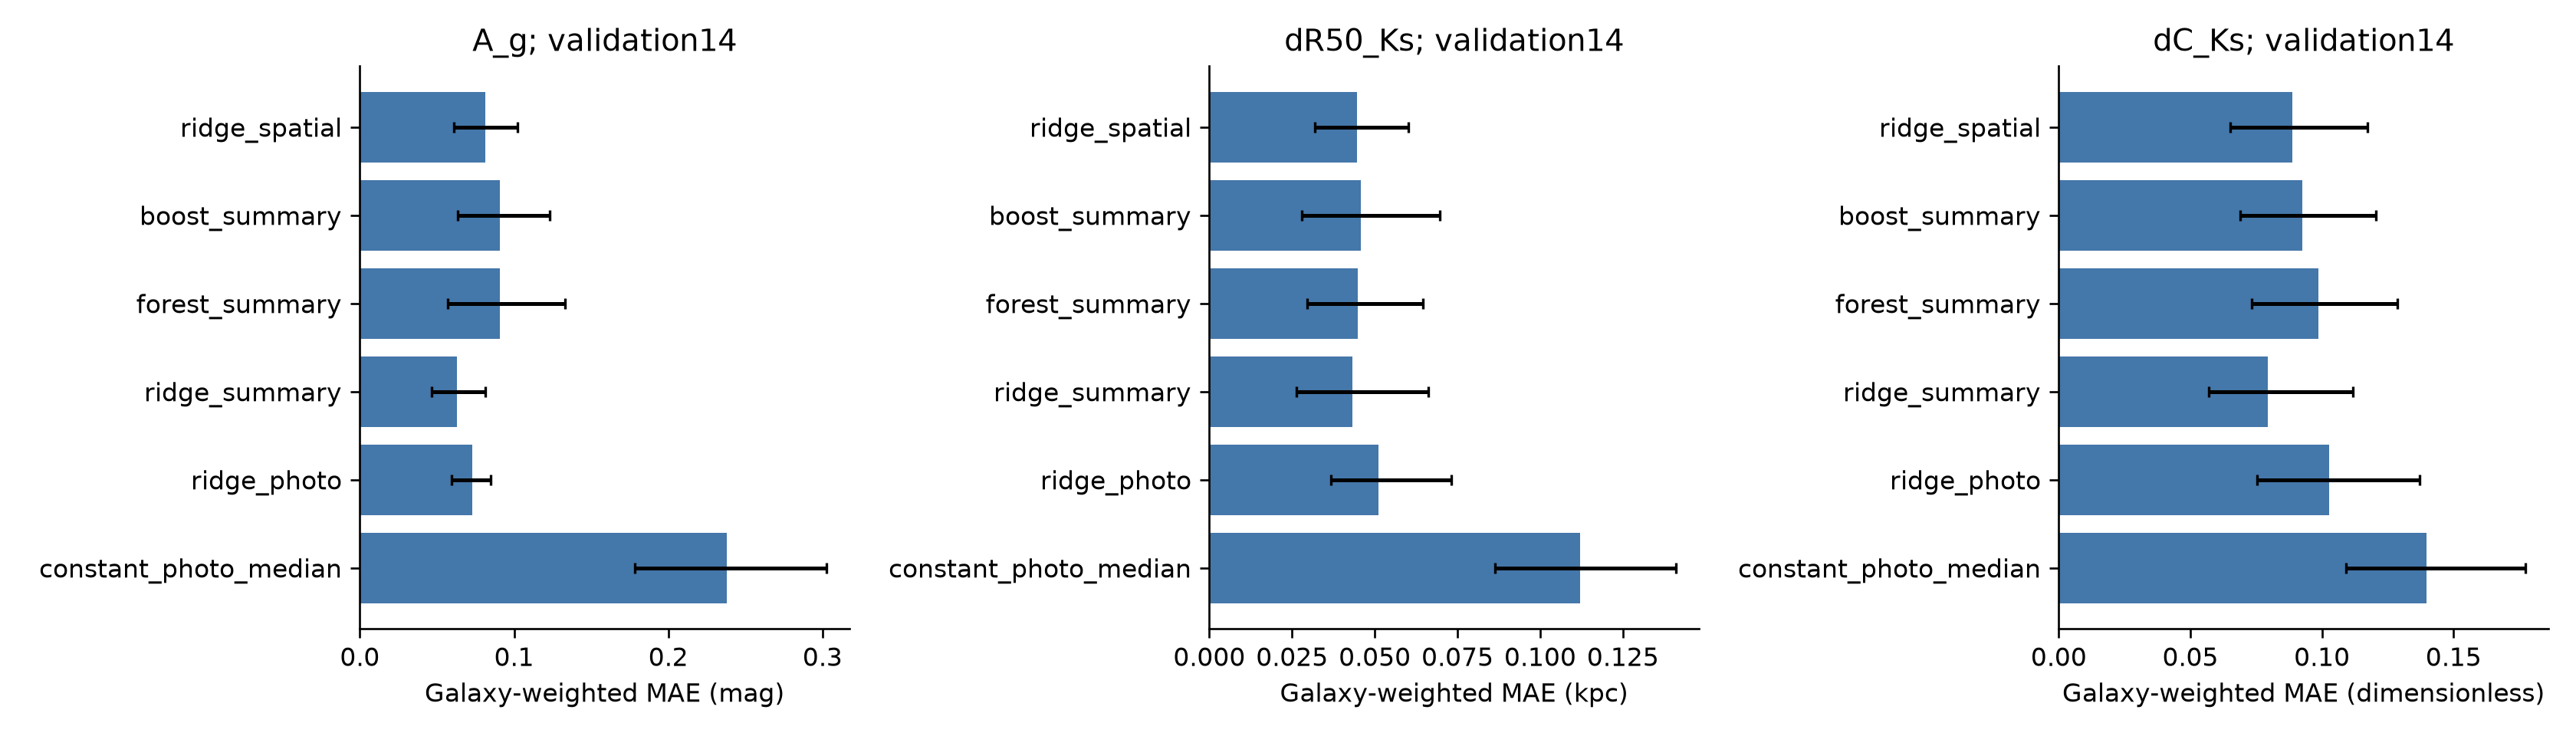

In [3]:
display(Image(filename=str(O/'figures/model_comparison.png')))

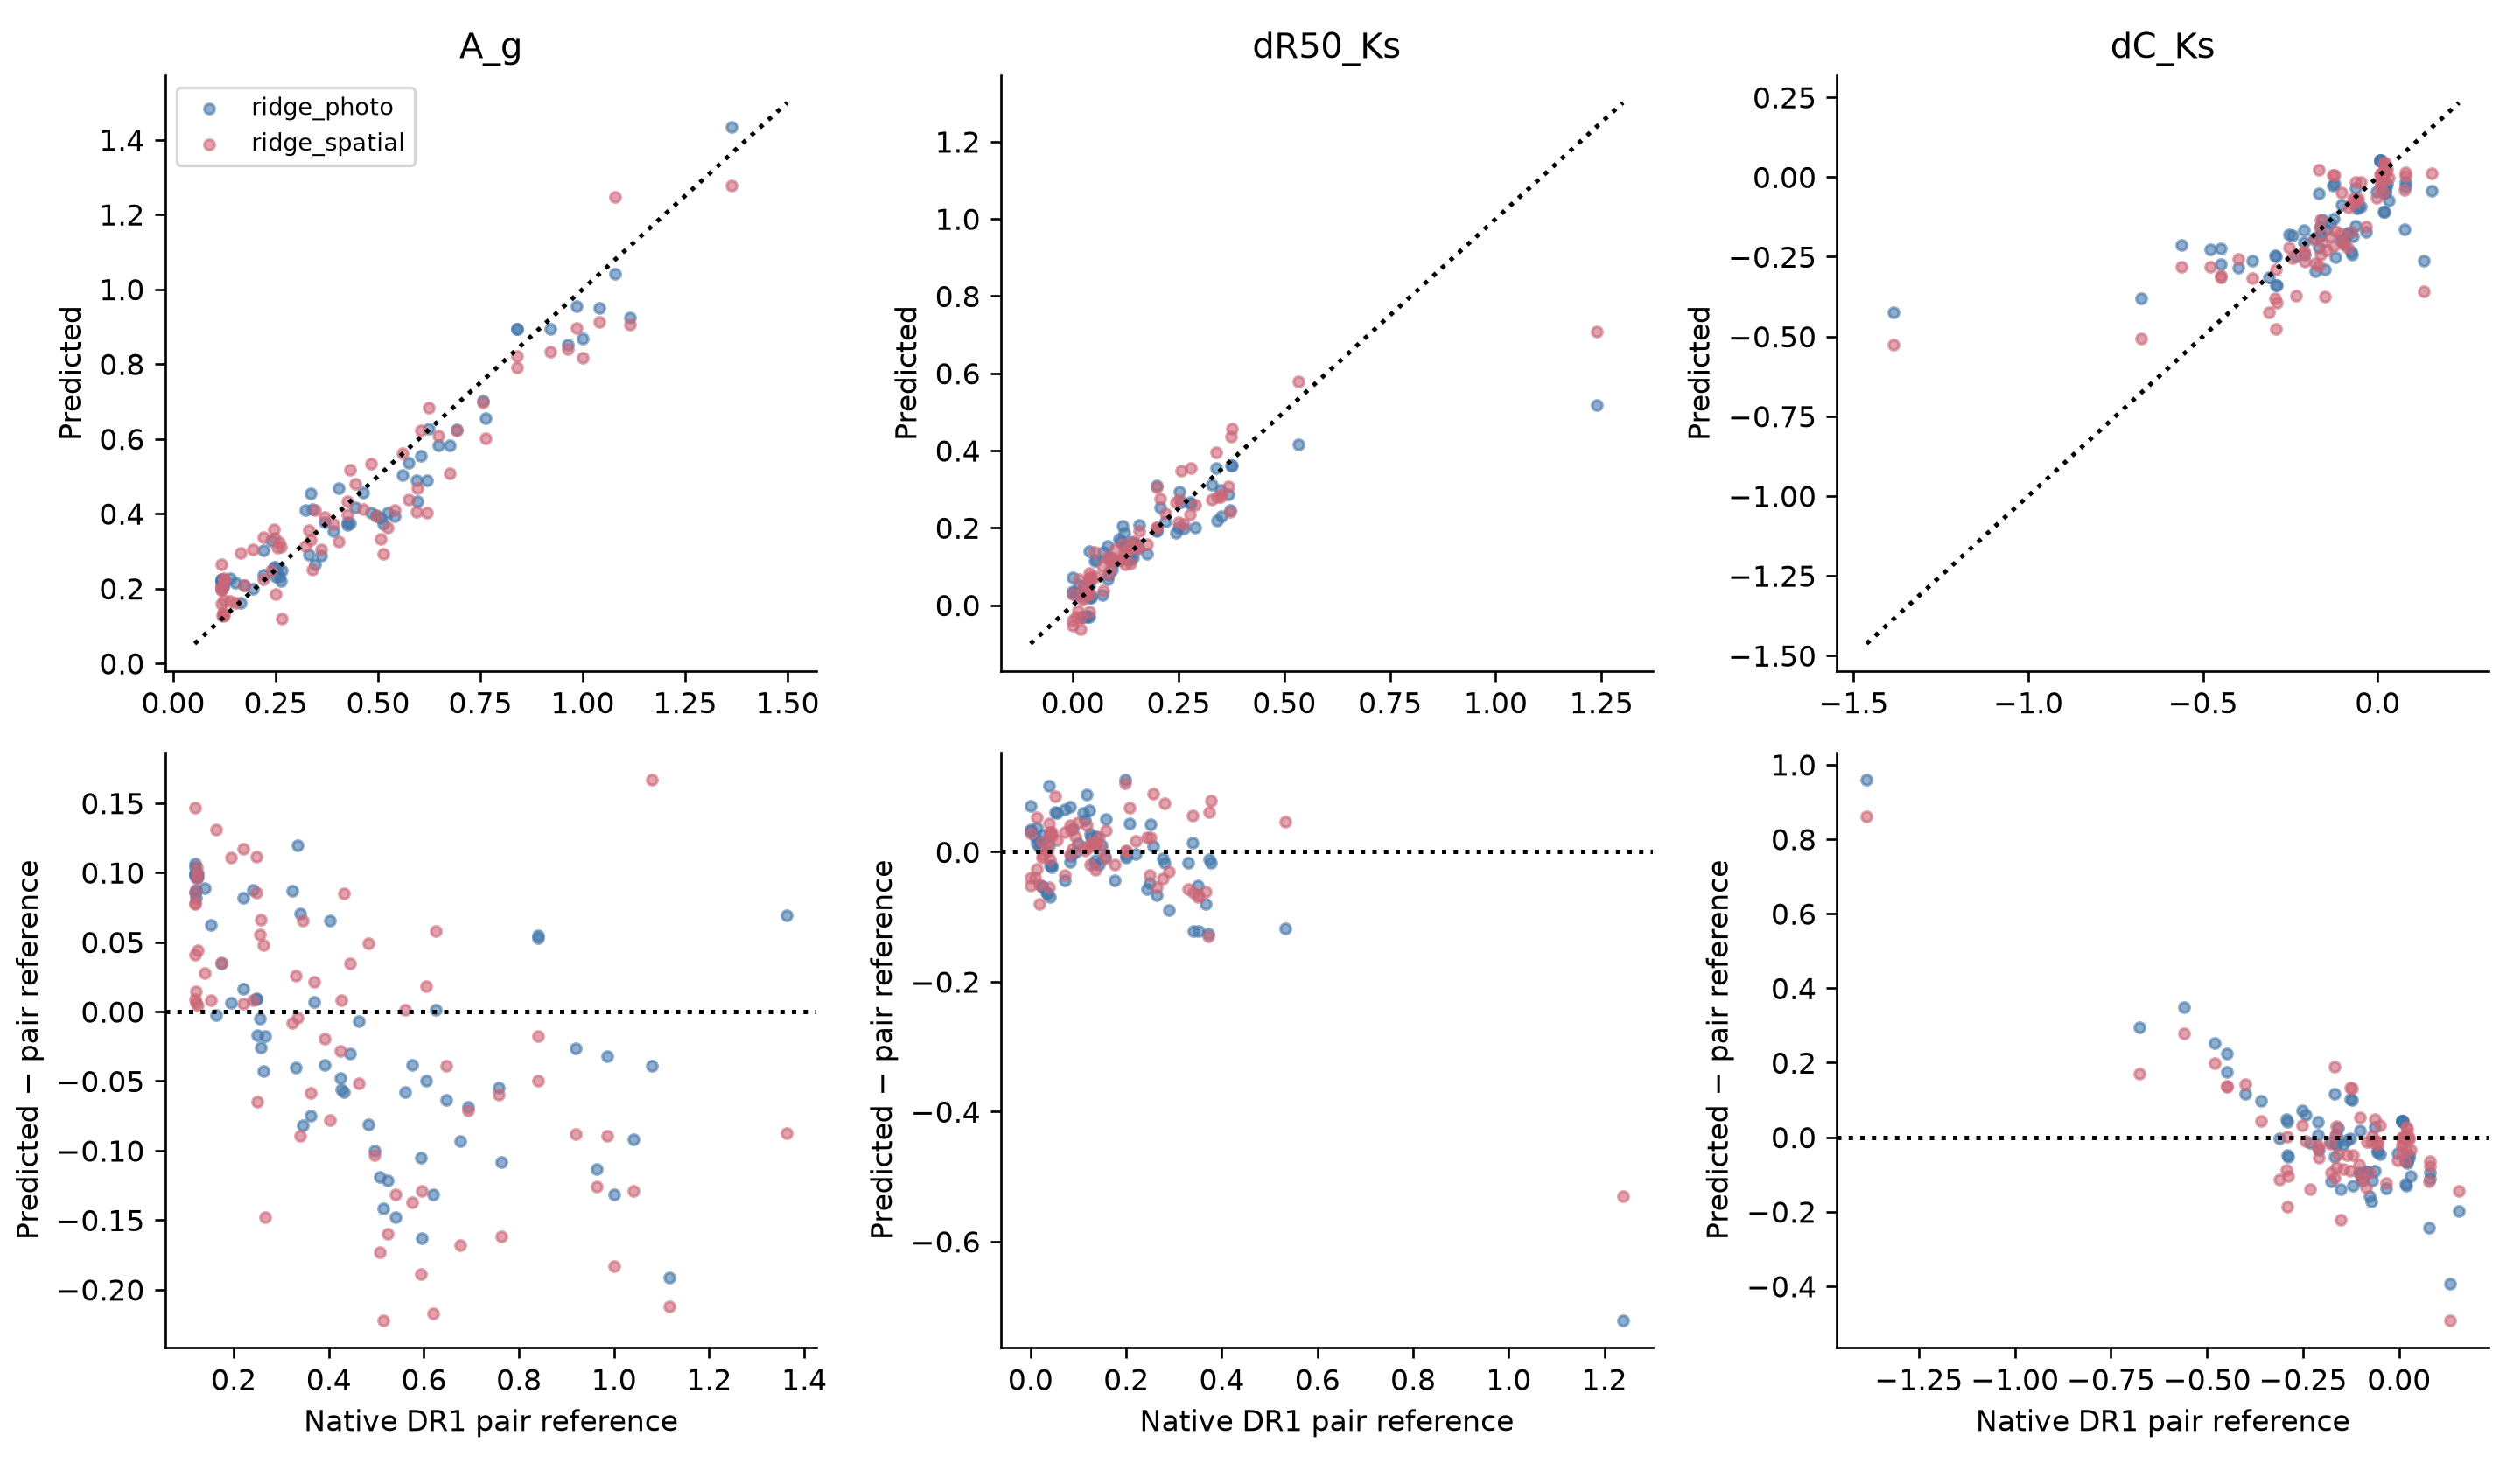

In [4]:
display(Image(filename=str(O/'figures/predictions_residuals.png')))

## NIR bands and resolution
Positive seeing-minus-GLAO MAE denotes an improvement. Intervals resample galaxies, conditional on fitted methods and the selected sample; no multiplicity correction or population-wide guarantee.

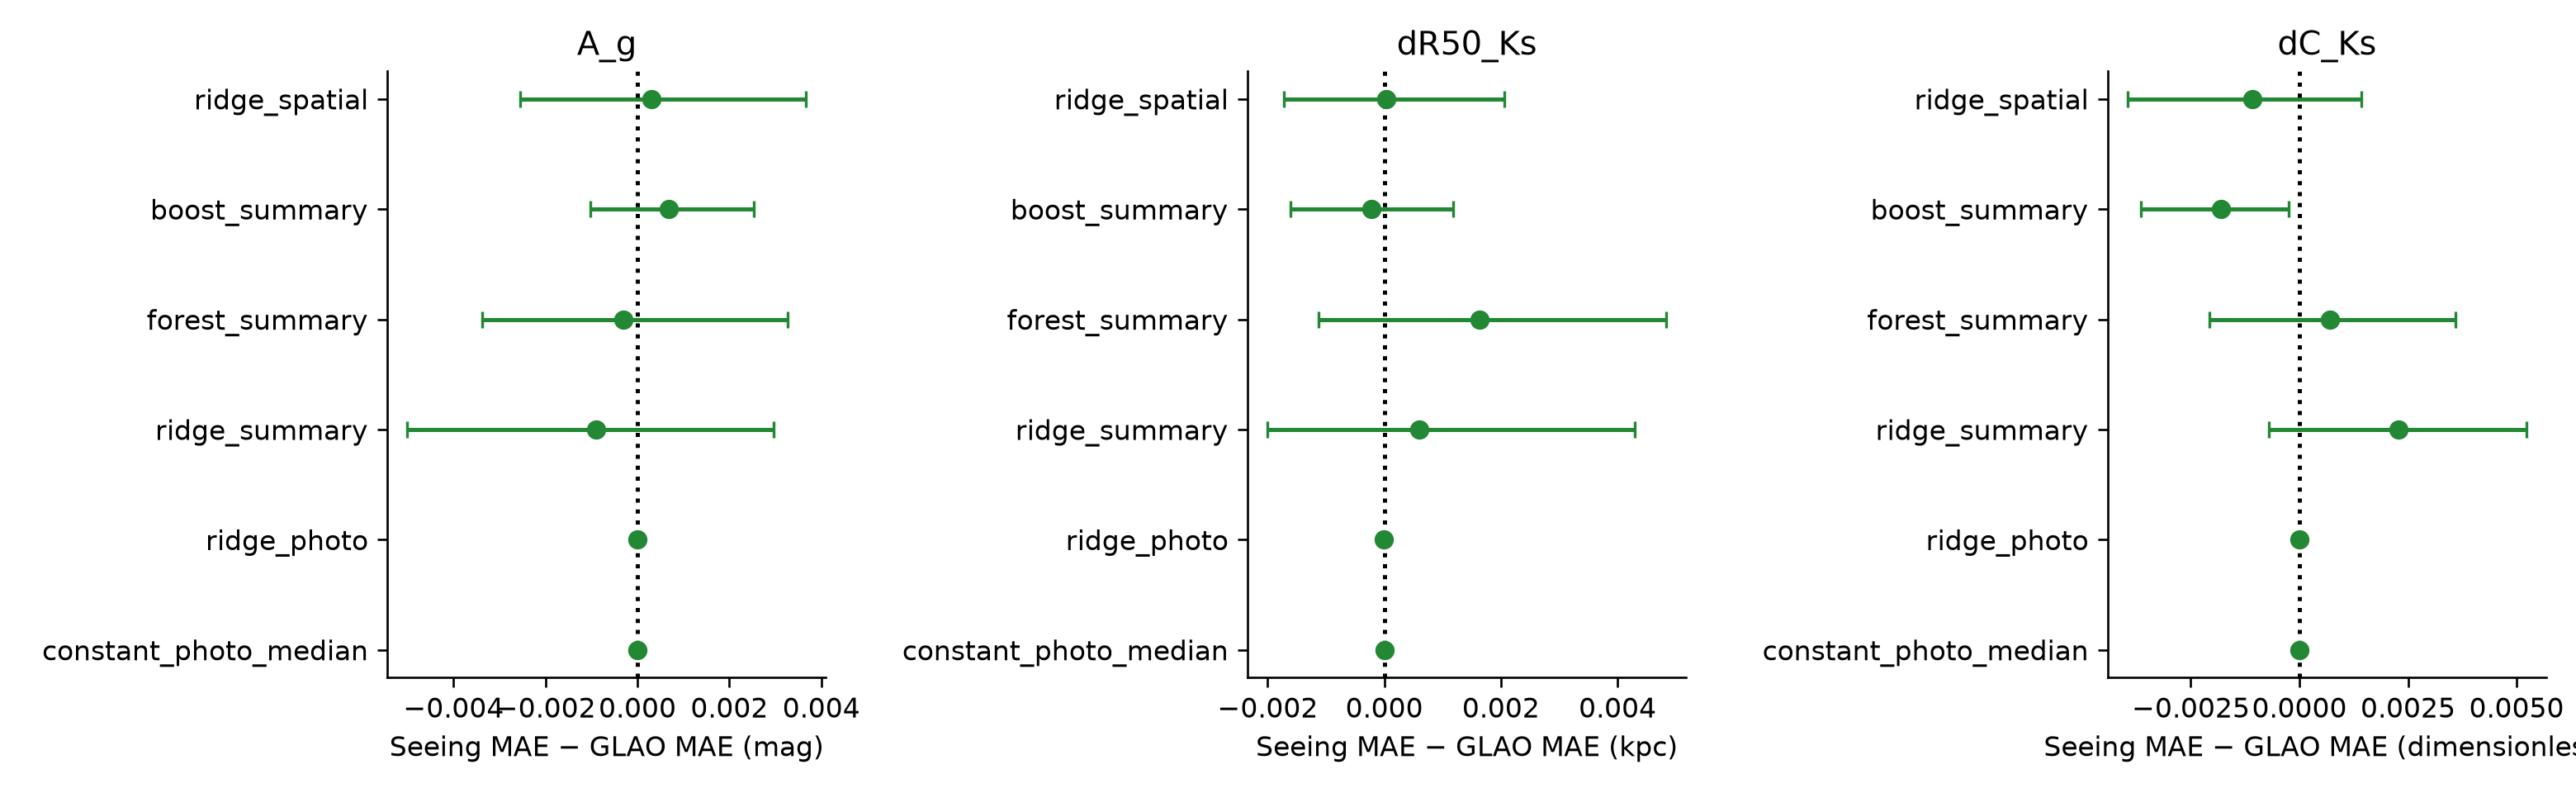

In [5]:
display(Image(filename=str(O/'figures/GLAO_increment.png')))

## Learning, uncertainty and OOD
Learning-curve points use development group CV with tuning inside each training subset. Error bars show fold scatter, not independent-galaxy confidence intervals. Interval calibration uses seven validation galaxies and assessment uses the other seven, with each score the maximum residual over all views/draws.

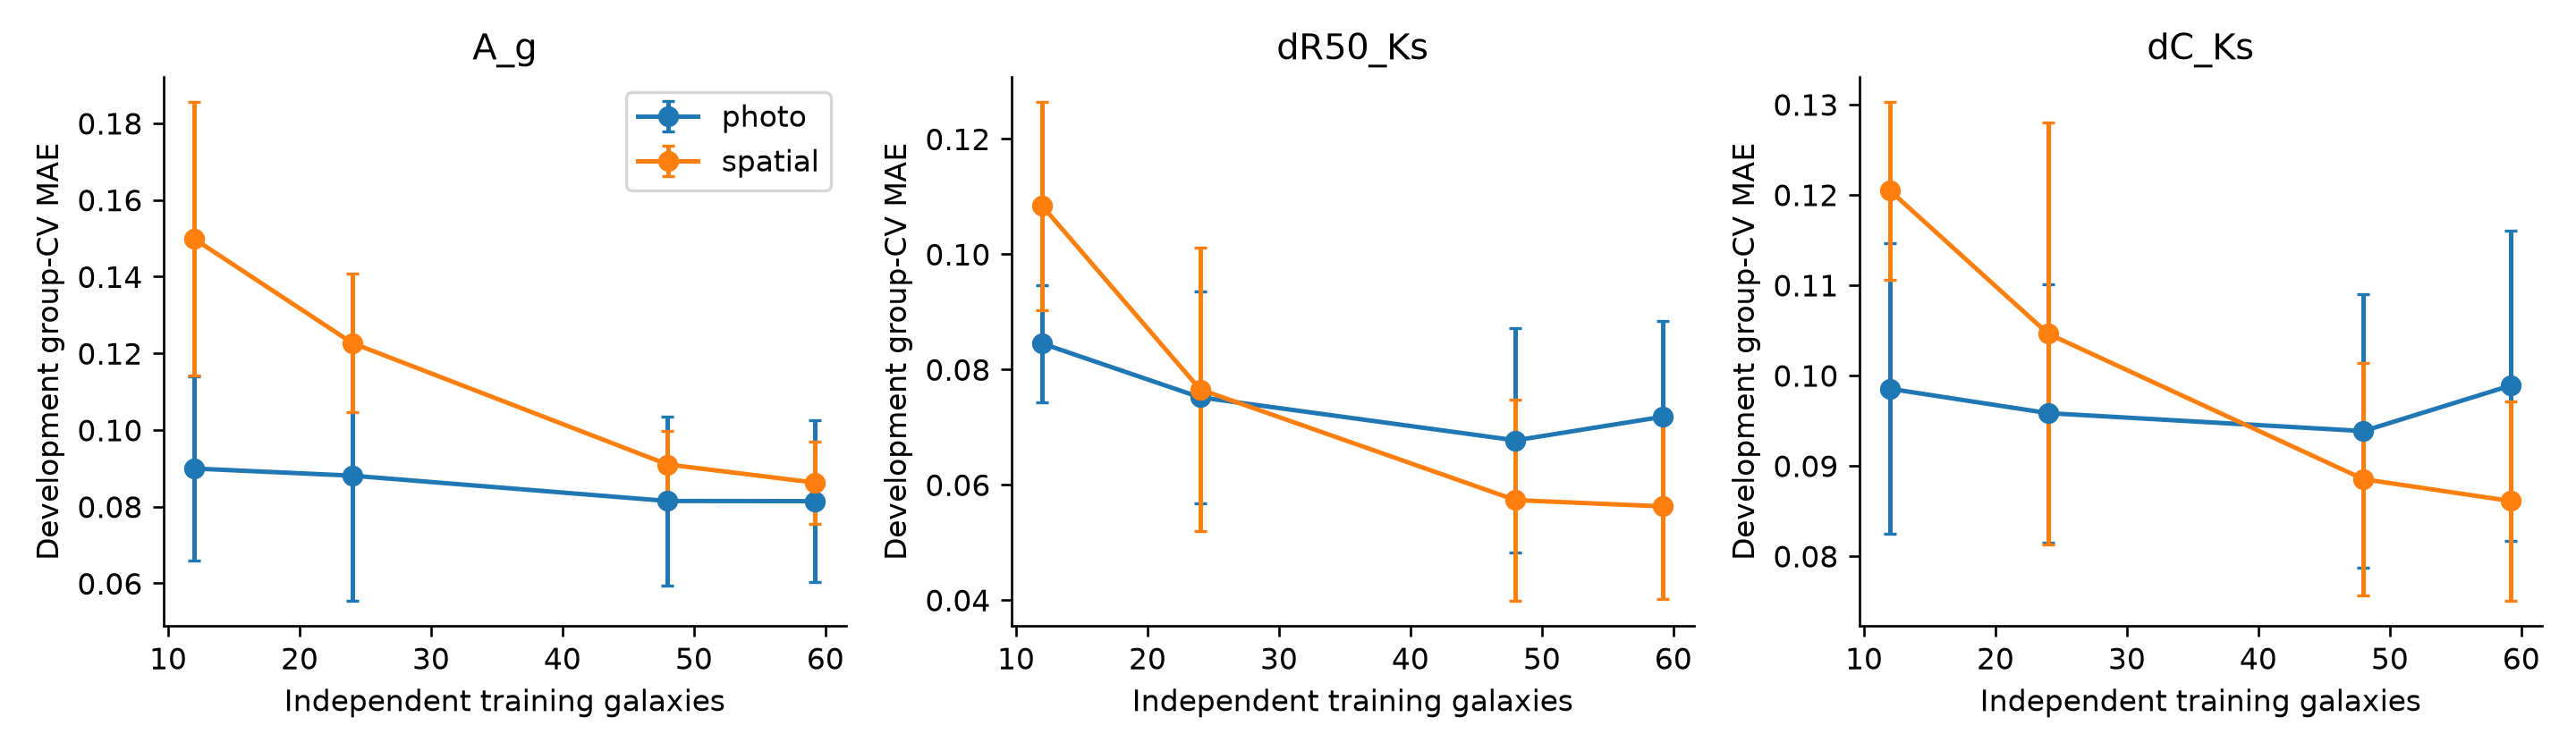

,tag,half_width,calibration_galaxies,assessment_galaxies,entire_galaxy_coverage,row_coverage,coverage_Wilson95_lo,coverage_Wilson95_hi,coverage_CI_scope
37,fixed12_nir_seeing_A_g_ridge_photo_,0.22120,7,7,1.00000,1.00000,0.64567,1.00000,binomial diagnostic on selected galaxies; exch...
48,fixed12_nir_seeing_dR50_Ks_ridge_spatial_,0.17088,7,7,0.85714,0.97143,0.48687,0.97432,binomial diagnostic on selected galaxies; exch...
55,fixed12_nir_seeing_dC_Ks_ridge_spatial_,0.49849,7,7,0.85714,0.97143,0.48687,0.97432,binomial diagnostic on selected galaxies; exch...


,tag,n_train,n_test,MAE,constant_MAE,setting
0,fixed12_nir_seeing_A_g_ridge_photo_,55,19,0.09557,0.34235,1.0
1,fixed12_nir_seeing_A_g_ridge_spatial_,55,19,0.09816,0.34235,10.0
2,fixed12_nir_seeing_dR50_Ks_ridge_photo_,55,19,0.07975,0.14459,100.0
3,fixed12_nir_seeing_dR50_Ks_ridge_spatial_,55,19,0.04812,0.14459,100.0
4,fixed12_nir_seeing_dC_Ks_ridge_photo_,55,19,0.09242,0.16725,10.0
5,fixed12_nir_seeing_dC_Ks_ridge_spatial_,55,19,0.07908,0.16725,100.0


In [6]:
display(Image(filename=str(O/'figures/learning_curves.png')))
cal=pd.read_csv(O/'uncertainty_calibration.csv')
display(cal[cal.tag.isin(['fixed12_nir_seeing_A_g_ridge_photo_','fixed12_nir_seeing_dR50_Ks_ridge_spatial_','fixed12_nir_seeing_dC_Ks_ridge_spatial_'])].round(5))
ood=pd.read_csv(O/'OOD_summary.csv');display(ood[ood.tag.str.contains('seeing')].round(5))

## Aperture and source-systematic limits

In [7]:
display(pd.read_csv(O/'aperture_target_sensitivity.csv').round(5))
display(pd.read_csv(O/'source_control_envelopes.csv').drop(columns='interpretation').round(5))

,target,median_galaxy_absolute_change,mean_galaxy_absolute_change,max_galaxy_absolute_change
0,A_g,0.02171,0.03065,0.17263
1,dR50_Ks,0.01868,0.04152,0.33010
2,dC_Ks,0.03108,0.03906,0.17876
3,A_Ks,0.00347,0.00601,0.03944
4,A_g_p50_1kpc,0.02275,0.05646,0.43245
5,A_g_IQR_1kpc,0.02933,0.06258,0.64295


,aperture,target,galaxies,median,max_abs
0,adaptive,A_g,4,0.12207,0.12433
1,adaptive,dR50_Ks,4,0.01045,0.03749
2,adaptive,dC_Ks,4,0.01419,0.23982
3,adaptive,A_g_p50_1kpc,4,0.11180,0.11907
4,adaptive,A_g_IQR_1kpc,4,0.00645,0.01211
5,fixed12,A_g,4,0.12138,0.12392
6,fixed12,dR50_Ks,4,0.01106,0.03918
7,fixed12,dC_Ks,4,0.01435,0.04596
8,fixed12,A_g_p50_1kpc,4,0.11115,0.11887
9,fixed12,A_g_IQR_1kpc,4,0.00688,0.01446


## HAWK-I-informed stress
O1/two-draw stress only; empirical HAWK-I PSF shapes and correlated-noise stresses are separate from nominal ULTIMATE. HAWK-I supplies no dust truth. The long-scale covariance component is an explicit sensitivity choice, not a calibrated ESO or ULTIMATE noise model.

In [8]:
display(pd.read_csv(O/'sensitivity_noise_response.csv').round(4))
s=pd.read_csv(O/'sensitivity_summary.csv');display(s[(s.stage=='validation')&(s.tag=='fixed12_nir_seeing_A_g_ridge_photo_')][['scenario','MAE','RMSE','bias','n_galaxies']].round(5))

,scenario,rho_x,rho_y,aperture_ratio_R2,aperture_ratio_R4,aperture_ratio_R8,aperture_ratio_R16,aperture_ratio_R32
0,white,-0.0002,0.0012,0.9992,0.9988,0.9956,0.9913,0.9923
1,local_covariance,0.2749,0.2934,1.3907,1.5112,1.5551,1.5720,1.5854
2,long_covariance,0.2895,0.3076,1.4394,1.7402,2.1647,2.5365,2.7215


,scenario,MAE,RMSE,bias,n_galaxies
1943,coarse_sampling,0.07254,0.08505,-0.02432,13
2195,elliptical_wings,0.07087,0.08507,-0.01770,13
2447,hawki_shape,0.07087,0.08507,-0.01770,13
2699,local_covariance,0.07299,0.08748,-0.01626,13
2951,long_covariance,0.07283,0.08743,-0.01039,13
3203,low_surface_brightness,0.09024,0.10455,0.00427,13
3455,nominal,0.07108,0.08517,-0.01835,13


## Takeaways

Read `scientific_report.md` for the quantitative conclusions, negative results and publication assessment. The notebook refit check verifies reproducibility of selected models; it does not validate source-product physical truth, simulation-to-real transfer or a unique three-dimensional geometry. The canonical project final20 evaluation is already complete; these supplementary models are validation-only and must not be tested on the spent final set.

## Verified canonical final result, reused without new inference
The pre-existing pipeline froze its own methods before final access and completed the project’s single final evaluation. Its positive-dust primary sample has16 galaxies;4 final source controls are separate. The following saved summary belongs to that canonical model family, **not** the supplementary refits above. No supplementary final inference has been run.

In [9]:
canonical=pd.read_csv(O.parent/'ml_expanded_20261028/recommended_performance.csv');display(canonical[(canonical.evaluation=='final_test')&(canonical.aperture=='adaptive')&(canonical.scenario=='GLAO_NIR')][['target','family','n_galaxies','MAE','RMSE','bias','galaxy_coverage']].round(5))

,target,family,n_galaxies,MAE,RMSE,bias,galaxy_coverage
0,A_g_IQR_1kpc,spatial_boost,16,0.07073,0.16395,-0.03196,0.8750
1,dC_g,spatial_boost,16,0.24453,0.32768,-0.09236,0.8125
2,A_g_p50_1kpc,spatial_forest,16,0.04412,0.13971,-0.02437,0.8125
3,dC_Ks,spatial_ridge,16,0.08869,0.13060,0.00419,0.8750
4,dR50_g,spatial_ridge,16,0.22361,0.31668,0.05156,0.9375
5,A_Ks,summary_ridge,16,0.01241,0.01632,0.00319,1.0000
6,A_g,summary_ridge,16,0.07408,0.10980,-0.04067,0.7500
7,dR50_Ks,summary_ridge,16,0.07987,0.11894,0.04779,0.9375
